<a href="https://colab.research.google.com/github/sairamvelpurii/Colab_Notebooks_AI/blob/main/Airbnb_Price_prediction_NyC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importing the dataset

In [2]:
import kagglehub
path = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")

Using Colab cache for faster access to the 'new-york-city-airbnb-open-data' dataset.


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv(path + "/AB_NYC_2019.csv")
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


Checking Dimensions

In [ ]:
# df.shape
# df.info()
# df.describe()

In [ ]:
# df.isnull().sum()

In [5]:
df.dropna(inplace=True)
df.isnull().sum()

,0
id,0
name,0
host_id,0
host_name,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [6]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.dtypes

df['id'] = df['id'].astype(object)
df['host_id'] = df['host_id'].astype(object)

df.dtypes

,0
id,object
name,object
host_id,object
host_name,object
neighbourhood_group,object
neighbourhood,object
latitude,float64
longitude,float64
room_type,object
price,int64


In [12]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [13]:
numerical_features = [
    'latitude',
    'longitude',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count',
    'availability_365'
]

categorical_features = [
    'neighbourhood_group',
    'neighbourhood',
    'room_type'
]

identifier_columns = [
    'id',
    'host_id',
    'name',
    'host_name'
]

target = 'price'

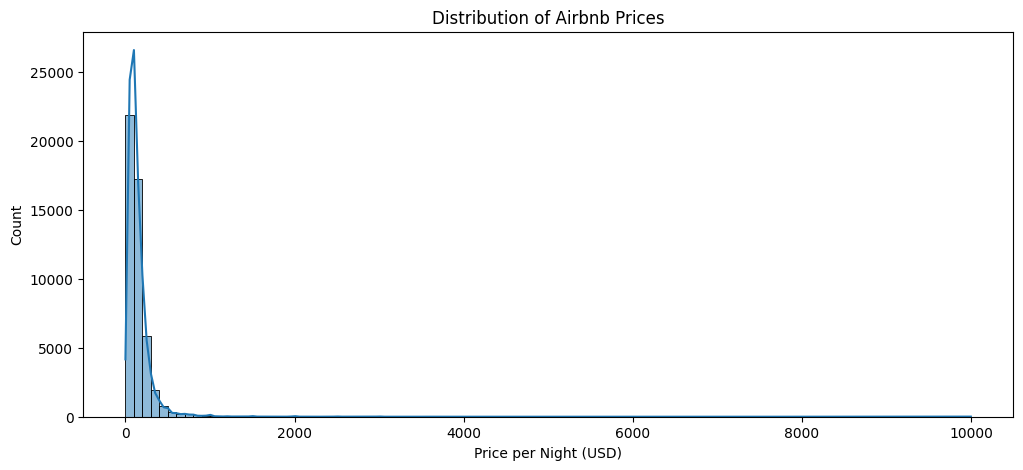

In [17]:
plt.figure(figsize=(12, 5))

sns.histplot(df['price'], bins=100, kde=True)

plt.title("Distribution of Airbnb Prices")
plt.xlabel("Price per Night (USD)")
plt.show()

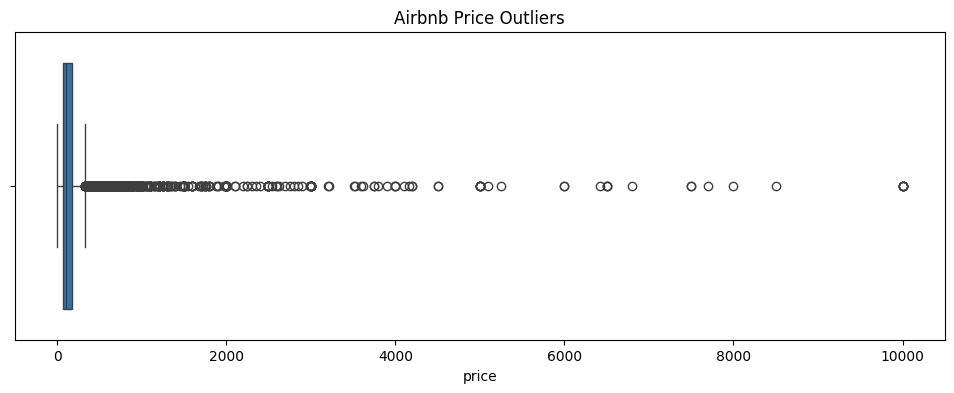

In [18]:
plt.figure(figsize=(12, 4))

sns.boxplot(x=df['price'])

plt.title("Airbnb Price Outliers")
plt.show()

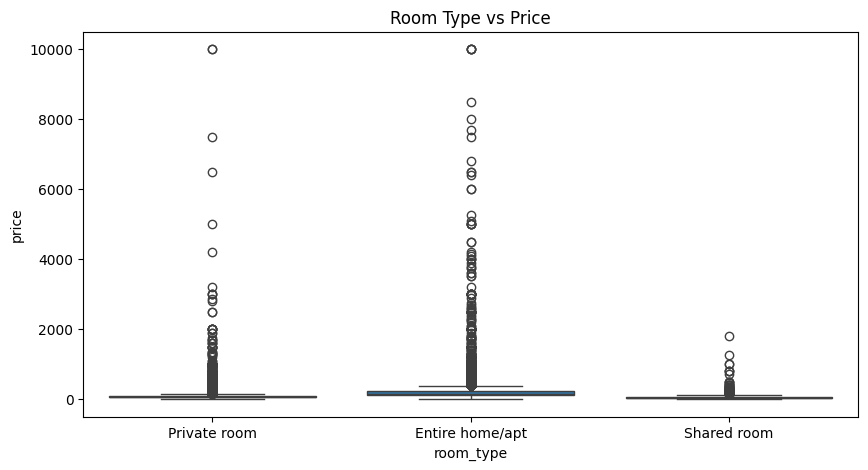

In [19]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='room_type',
    y='price'
)

plt.title("Room Type vs Price")
plt.show()

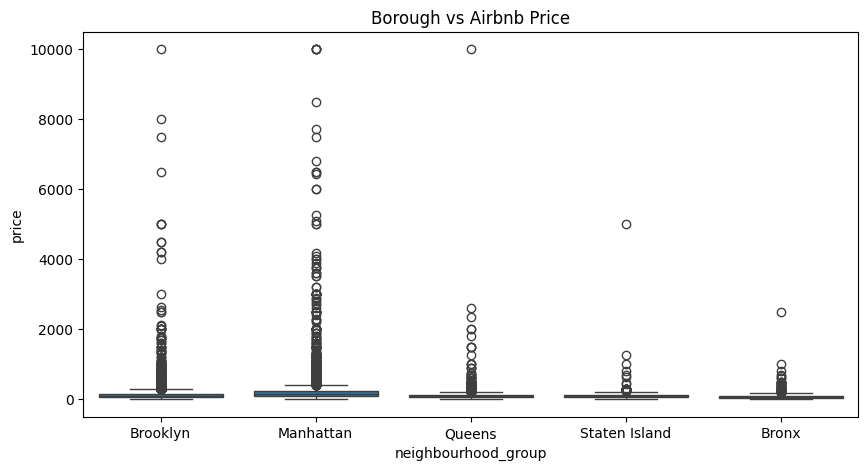

In [20]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='neighbourhood_group',
    y='price'
)

plt.title("Borough vs Airbnb Price")
plt.show()

### Target Variable Characterization & Advanced EDA
In this section, we calculate the statistical properties of the target distribution and perform bivariate and multivariate correlation analysis.

Target (Price) Skewness: 19.12
Target (Price) Kurtosis: 585.67


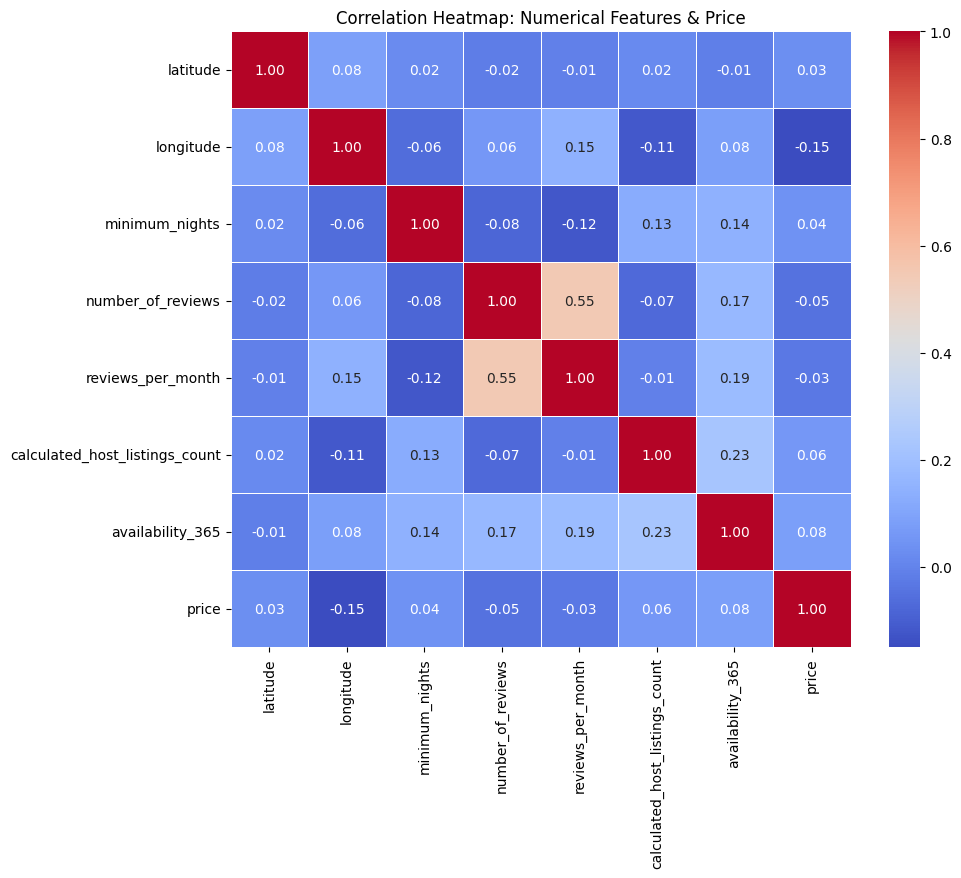

In [21]:
import numpy as np

# 1. Calculate Skewness and Kurtosis of Price
price_skew = df['price'].skew()
price_kurt = df['price'].kurt()

print(f"Target (Price) Skewness: {price_skew:.2f}")
print(f"Target (Price) Kurtosis: {price_kurt:.2f}")

# 2. Correlation Heatmap of Numerical Features
plt.figure(figsize=(10, 8))
corr_matrix = df[numerical_features + ['price']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title("Correlation Heatmap: Numerical Features & Price")
plt.show()

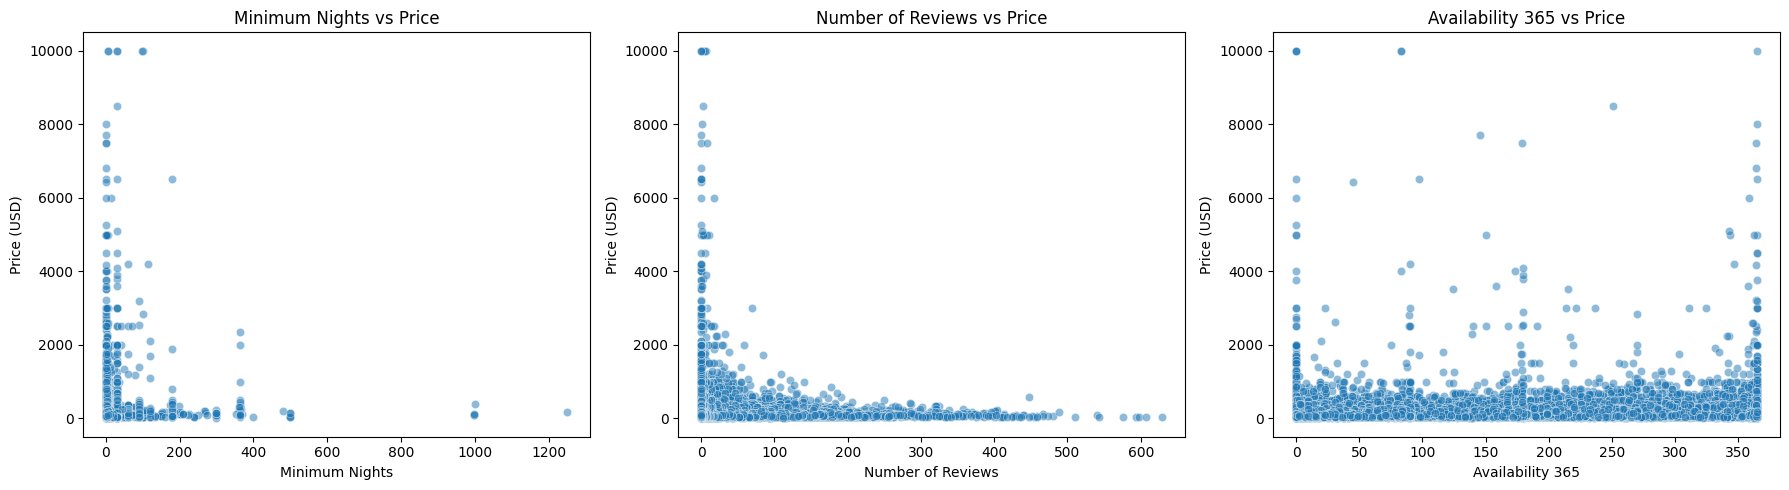

In [22]:
# 3. Scatter Plots for Key Continuous Features vs. Price
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Minimum Nights vs Price
sns.scatterplot(data=df, x='minimum_nights', y='price', alpha=0.5, ax=axes[0])
axes[0].set_title('Minimum Nights vs Price')
axes[0].set_xlabel('Minimum Nights')
axes[0].set_ylabel('Price (USD)')

# Number of Reviews vs Price
sns.scatterplot(data=df, x='number_of_reviews', y='price', alpha=0.5, ax=axes[1])
axes[1].set_title('Number of Reviews vs Price')
axes[1].set_xlabel('Number of Reviews')
axes[1].set_ylabel('Price (USD)')

# Availability 365 vs Price
sns.scatterplot(data=df, x='availability_365', y='price', alpha=0.5, ax=axes[2])
axes[2].set_title('Availability 365 vs Price')
axes[2].set_xlabel('Availability 365')
axes[2].set_ylabel('Price (USD)')

plt.tight_layout()
plt.show()

### Phase 3: Data Cleaning - Investigating Outliers and Anomalies
Here, we inspect zero prices, calculate percentiles for the `price` column to define outlier thresholds, and look at extreme values of `minimum_nights`.

In [23]:
# 1. Check for Zero or Negative Prices
zero_prices = (df['price'] <= 0).sum()
print(f"Number of listings with price <= 0: {zero_prices}")

# 2. Check Percentiles of Price to Understand Distribution Edge Cases
percentiles = [50, 90, 95, 99, 99.5, 99.9]
for p in percentiles:
    val = np.percentile(df['price'], p)
    print(f"{p}th percentile of Price: ${val:.2f}")

# 3. Check Percentiles of Minimum Nights
for p in [50, 90, 95, 99, 99.9]:
    val = np.percentile(df['minimum_nights'], p)
    print(f"{p}th percentile of Minimum Nights: {val:.1f} nights")

Number of listings with price <= 0: 11
50th percentile of Price: $106.00
90th percentile of Price: $269.00
95th percentile of Price: $355.00
99th percentile of Price: $799.00
99.5th percentile of Price: $1000.00
99.9th percentile of Price: $3000.00
50th percentile of Minimum Nights: 3.0 nights
90th percentile of Minimum Nights: 28.0 nights
95th percentile of Minimum Nights: 30.0 nights
99th percentile of Minimum Nights: 45.0 nights
99.9th percentile of Minimum Nights: 354.6 nights


### Applying Outlier Filters and Removing Invalid Records
We will remove listings with a price of 0, limit our price range to the 99th percentile ($799), and limit the minimum nights stay to 45 nights.

In [24]:
# Get original shape before cleaning
orig_shape = df.shape

# Filter out price <= 0 and outliers above the 99th percentile
df_clean = df[(df['price'] > 0) & (df['price'] <= 799)].copy()

# Filter out extreme minimum_nights (above 45 nights)
df_clean = df_clean[df_clean['minimum_nights'] <= 45]

# Compare shapes
new_shape = df_clean.shape
removed_rows = orig_shape[0] - new_shape[0]
percent_retained = (new_shape[0] / orig_shape[0]) * 100

print(f"Original dataset shape: {orig_shape}")
print(f"Cleaned dataset shape: {new_shape}")
print(f"Removed {removed_rows} rows ({100 - percent_retained:.2f}% of data)")
print(f"Retained {percent_retained:.2f}% of the data")

Original dataset shape: (48895, 16)
Cleaned dataset shape: (47964, 16)
Removed 931 rows (1.90% of data)
Retained 98.10% of the data


### Phase 4: Feature Engineering
We extract temporal components from `last_review` and apply log transformations to highly skewed numerical features.

In [25]:
# 1. Convert last_review to datetime
df_clean['last_review'] = pd.to_datetime(df_clean['last_review'])

# 2. Extract temporal features
df_clean['review_year'] = df_clean['last_review'].dt.year
df_clean['review_month'] = df_clean['last_review'].dt.month

# 3. Calculate review recency (days since the most recent review in the entire dataset)
most_recent_date = df_clean['last_review'].max()
df_clean['days_since_last_review'] = (most_recent_date - df_clean['last_review']).dt.days

# 4. Fill missing values created by date features with placeholders
# If a listing had 0 reviews, its last_review date was NaN.
# We will fill missing temporal values with a separate flag value (e.g., 0 for year/month) or median/imputation in Preprocessing.
df_clean['review_year'] = df_clean['review_year'].fillna(0).astype(int)
df_clean['review_month'] = df_clean['review_month'].fillna(0).astype(int)
df_clean['days_since_last_review'] = df_clean['days_since_last_review'].fillna(-1)  # -1 represents "never reviewed"

# 5. Apply Log Transform to Skewed Numerical Features
df_clean['log_minimum_nights'] = np.log1p(df_clean['minimum_nights'])
df_clean['log_number_of_reviews'] = np.log1p(df_clean['number_of_reviews'])

# Inspect engineered columns
print(df_clean[['minimum_nights', 'log_minimum_nights', 'review_year', 'review_month', 'days_since_last_review']].head())
print(f"Current dataframe shape: {df_clean.shape}")

   minimum_nights  log_minimum_nights  review_year  review_month  \
0               1            0.693147         2018            10   
1               1            0.693147         2019             5   
2               3            1.386294            0             0   
3               1            0.693147         2019             7   
4              10            2.397895         2018            11   

   days_since_last_review  
0                   262.0  
1                    48.0  
2                    -1.0  
3                     3.0  
4                   231.0  
Current dataframe shape: (47964, 21)


### Phase 5: Data Preprocessing Pipeline
We split the cleaned dataset into training and test sets, define numerical and categorical preprocessing pipelines, and bundle them into a unified `ColumnTransformer`.

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# 1. Define Features and Target
# We will use the original non-skewed features or their log versions as appropriate
features_to_use = [
    'latitude', 'longitude',
    'log_minimum_nights', 'log_number_of_reviews',
    'reviews_per_month', 'calculated_host_listings_count', 'availability_365',
    'review_year', 'review_month', 'days_since_last_review',
    'neighbourhood_group', 'room_type'
]

X = df_clean[features_to_use]
y = df_clean['price']

# 2. Train-Test Split (80% Train, 20% Test for validation)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Separate Features by Preprocessing Type
numeric_cols = [
    'latitude', 'longitude',
    'log_minimum_nights', 'log_number_of_reviews',
    'reviews_per_month', 'calculated_host_listings_count', 'availability_365',
    'review_year', 'review_month', 'days_since_last_review'
]

categorical_cols = ['neighbourhood_group', 'room_type']

# 4. Construct Sub-Pipelines
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  # Imputes any remaining missing values safely
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 5. Combine using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

# Fit and transform training features to inspect
X_train_processed = preprocessor.fit_transform(X_train)
print(f"Training set shape: {X_train.shape}")
print(f"Processed Training matrix shape: {X_train_processed.shape}")

Training set shape: (38371, 12)
Processed Training matrix shape: (38371, 18)


### Phase 6: Machine Learning Model Training - Baseline Models
We train baseline linear estimators (Linear Regression, Ridge, Lasso) and evaluate them using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) on the validation set.

In [27]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Define the base models we want to train first
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.1)
}

# Store metrics
results = {}

for name, model in models.items():
    # Create a full pipeline containing the preprocessor and the estimator
    full_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])

    # Fit the model on the training set
    full_pipeline.fit(X_train, y_train)

    # Make predictions on the validation (test) split
    y_pred = full_pipeline.predict(X_test)

    # Calculate metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results[name] = {'MAE': mae, 'RMSE': rmse, 'R2': r2}

# Display baseline results
import pandas as pd
results_df = pd.DataFrame(results).T
print(results_df)

                         MAE       RMSE        R2
Linear Regression  52.438870  82.737859  0.369030
Ridge Regression   52.436821  82.737253  0.369039
Lasso Regression   52.346416  82.721892  0.369273


### Phase 6: Machine Learning Model Training - Ensemble and Boosting Models
Now we train ensemble estimators (Random Forest, HistGradientBoosting, and XGBoost) and compare them side-by-side with our baseline linear estimators.

In [28]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor

# Define our advanced ensemble models
advanced_models = {
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42),
    'XGBoost': XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
}

# Train and collect metrics for advanced models
for name, model in advanced_models.items():
    full_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])

    # Fit on training data
    full_pipeline.fit(X_train, y_train)

    # Predict on validation data
    y_pred = full_pipeline.predict(X_test)

    # Calculate metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results[name] = {'MAE': mae, 'RMSE': rmse, 'R2': r2}

# Display consolidated results for all models
results_df = pd.DataFrame(results).T
print(results_df.sort_values(by='MAE'))

                            MAE       RMSE        R2
XGBoost               44.804775  74.090679  0.494027
HistGradientBoosting  44.859987  74.169481  0.492950
Random Forest         45.024063  74.872120  0.483297
Lasso Regression      52.346416  82.721892  0.369273
Ridge Regression      52.436821  82.737253  0.369039
Linear Regression     52.438870  82.737859  0.369030


### Phase 7: Model Evaluation - Best Model (XGBoost) Diagnostics
We analyze the residual errors, prediction distributions, and actual vs. predicted values for our optimized XGBoost model.

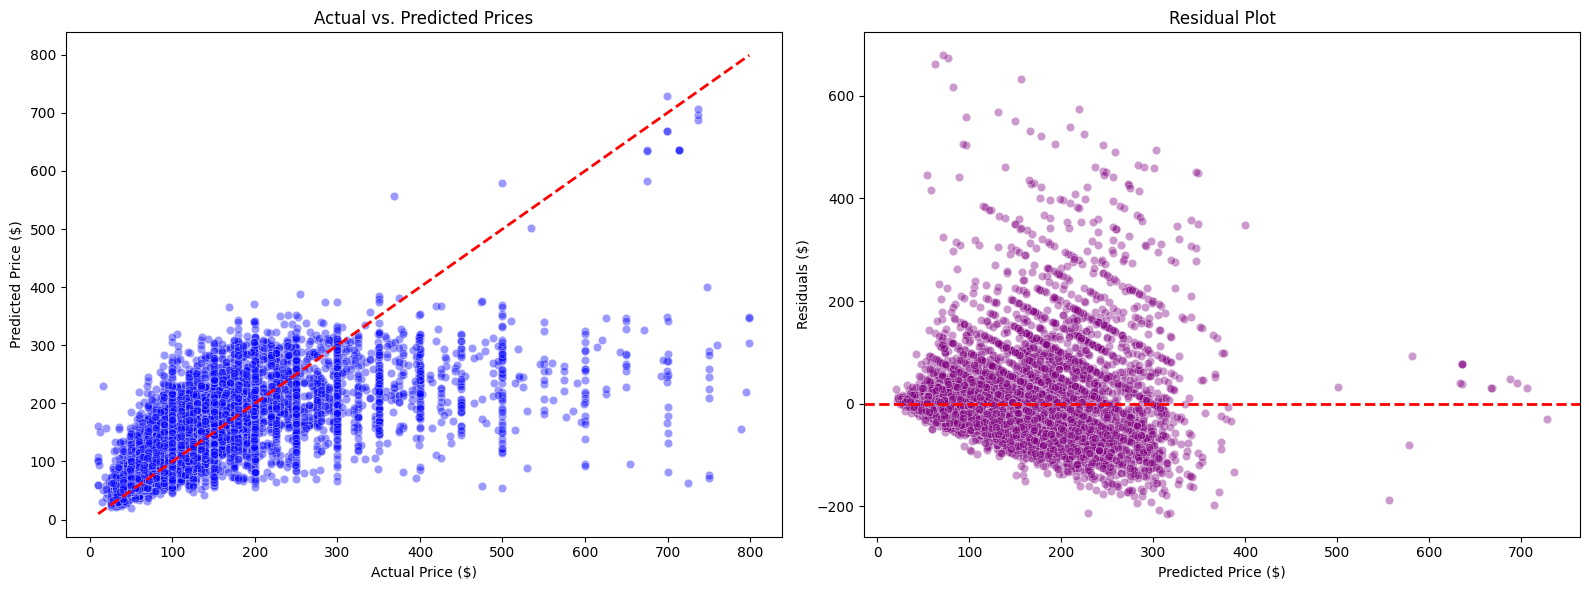

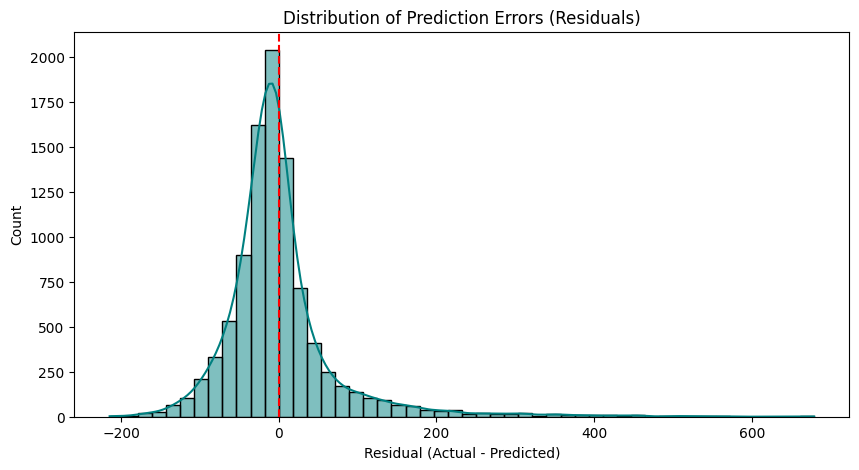

In [29]:
# 1. Re-train or fetch the best pipeline (XGBoost)
best_model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1))
])

best_model_pipeline.fit(X_train, y_train)
y_pred_xgb = best_model_pipeline.predict(X_test)
residuals = y_test - y_pred_xgb

# 2. Diagnostic Plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Actual vs. Predicted
sns.scatterplot(x=y_test, y=y_pred_xgb, alpha=0.4, ax=axes[0], color='blue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title("Actual vs. Predicted Prices")
axes[0].set_xlabel("Actual Price ($)")
axes[0].set_ylabel("Predicted Price ($)")

# Plot 2: Residual Plot
sns.scatterplot(x=y_pred_xgb, y=residuals, alpha=0.4, ax=axes[1], color='purple')
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_title("Residual Plot")
axes[1].set_xlabel("Predicted Price ($)")
axes[1].set_ylabel("Residuals ($)")

plt.tight_layout()
plt.show()

# 3. Distribution of Errors
plt.figure(figsize=(10, 5))
sns.histplot(residuals, bins=50, kde=True, color='teal')
plt.axvline(x=0, color='red', linestyle='--')
plt.title("Distribution of Prediction Errors (Residuals)")
plt.xlabel("Residual (Actual - Predicted)")
plt.show()

### Phase 8: Hyperparameter Optimization using RandomizedSearchCV
We define a search space for XGBoost's key hyperparameters and search for the best configuration using 3-fold cross-validation on our training split.

In [30]:
from sklearn.model_selection import RandomizedSearchCV

# 1. Define base model within pipeline structure
tuning_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(random_state=42, n_jobs=-1))
])

# 2. Define hyperparameter search grid
# Note: we use 'regressor__' prefix to specify parameters belonging to the regressor step in our pipeline
param_distributions = {
    'regressor__n_estimators': [100, 150, 200],
    'regressor__max_depth': [4, 6, 8],
    'regressor__learning_rate': [0.03, 0.1, 0.15],
    'regressor__subsample': [0.8, 1.0]
}

# 3. Setup RandomizedSearchCV
xgb_random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=6,  # Explores 6 random combinations to stay within Colab time limits
    cv=3,       # 3-fold cross-validation
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# 4. Fit the tuner on training data
print("Starting Hyperparameter Tuning... This may take a moment...")
xgb_random_search.fit(X_train, y_train)

# 5. Print Best Parameters and validation performance
print(f"Best Hyperparameters found: {xgb_random_search.best_params_}")
best_val_mae = -xgb_random_search.best_score_
print(f"Best cross-validated training MAE: ${best_val_mae:.2f}")

Starting Hyperparameter Tuning... This may take a moment...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Hyperparameters found: {'regressor__subsample': 0.8, 'regressor__n_estimators': 100, 'regressor__max_depth': 8, 'regressor__learning_rate': 0.03}
Best cross-validated training MAE: $44.94


### Phase 9: Model Interpretation - Global Feature Importance
We extract and plot the feature importances from our trained best-performing XGBoost model.

/tmp/ipykernel_516/3855859720.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')


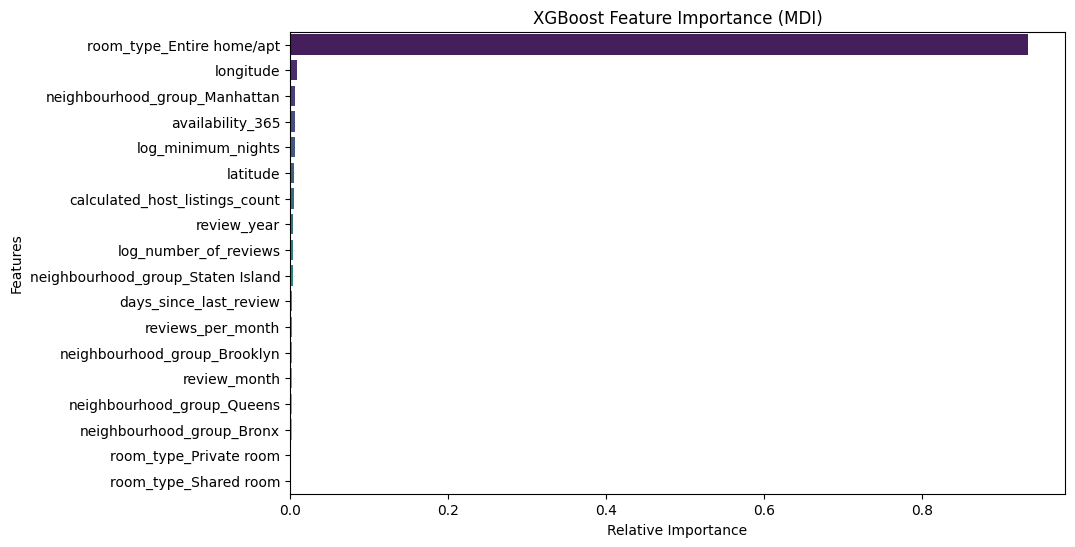

In [31]:
# 1. Train the final optimized model using the best hyperparameters found
final_model = XGBRegressor(
    n_estimators=100,
    max_depth=8,
    learning_rate=0.03,
    subsample=0.8,
    random_state=42,
    n_jobs=-1
)

final_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', final_model)
])

final_pipeline.fit(X_train, y_train)

# 2. Extract Feature Importances
# Get the feature names from the ColumnTransformer
cat_features_transformed = final_pipeline.named_steps['preprocessor']\
    .named_transformers_['cat']\
    .named_steps['onehot']\
    .get_feature_names_out(categorical_cols).tolist()

all_feature_names = numeric_cols + cat_features_transformed
importances = final_pipeline.named_steps['regressor'].feature_importances_

# 3. Construct Dataframe for Plotting
importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 4. Plot Feature Importance
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title("XGBoost Feature Importance (MDI)")
plt.xlabel("Relative Importance")
plt.ylabel("Features")
plt.show()

### Phase 9: Model Interpretation (SHAP Analysis)
In this section, we install the `shap` package, extract the preprocessed feature matrix, and generate a SHAP summary plot to understand both the importance and direction of our features' impact on pricing.

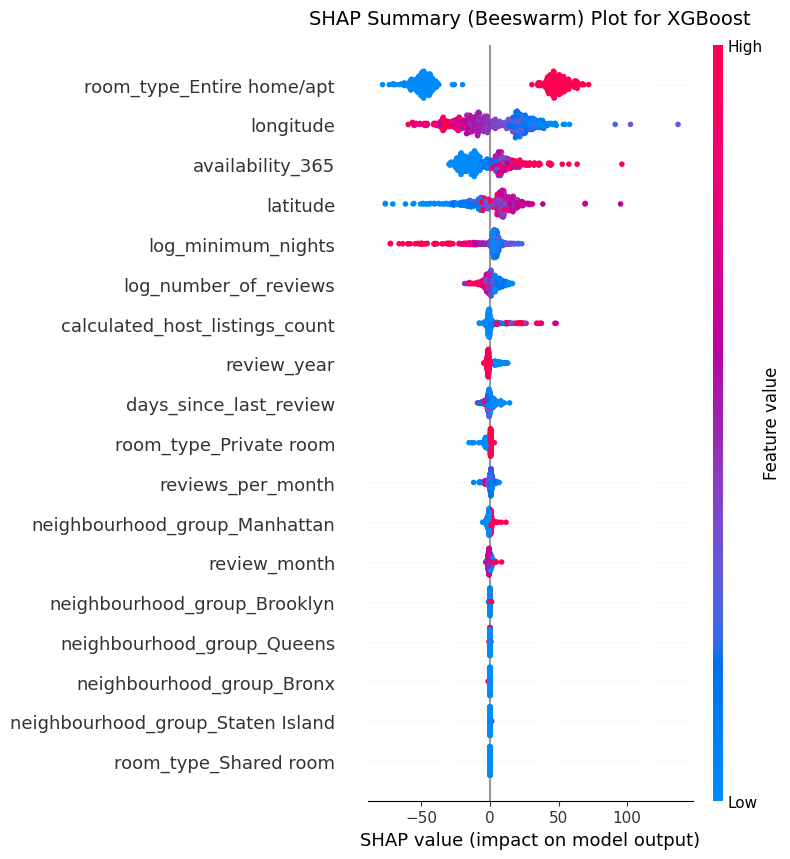

In [32]:
!pip install shap -q

import shap

# 1. Transform validation/test features using our pipeline's fitted preprocessor
X_test_processed_flat = final_pipeline.named_steps['preprocessor'].transform(X_test)

# 2. Convert to a DataFrame with explicit feature names for clear visualization
X_test_processed_df = pd.DataFrame(
    X_test_processed_flat,
    columns=all_feature_names
)

# 3. Create the SHAP Explainer using the trained XGBoost model from the pipeline
explainer = shap.TreeExplainer(final_pipeline.named_steps['regressor'])

# Calculate SHAP values for a sample of the test set to optimize execution speed
shap_sample = X_test_processed_df.sample(500, random_state=42)
shap_values = explainer(shap_sample)

# 4. Generate SHAP Beeswarm Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, shap_sample, show=False)
plt.title("SHAP Summary (Beeswarm) Plot for XGBoost", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

### Phase 10: Final Model Evaluation, Saving, and Real-Time Inference Simulation
In this final phase, we compute the ultimate validation metrics, serialize our end-to-end pipeline using `joblib`, and build an interactive prediction simulation function.

In [33]:
import joblib
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Evaluate the Final Optimized Pipeline on the Test Set
y_final_pred = final_pipeline.predict(X_test)

final_mae = mean_absolute_error(y_test, y_final_pred)
final_rmse = np.sqrt(mean_squared_error(y_test, y_final_pred))
final_r2 = r2_score(y_test, y_final_pred)

print("=== FINAL GENERALIZATION PERFORMANCE ON TEST SET ===")
print(f"Final Mean Absolute Error (MAE): ${final_mae:.2f}")
print(f"Final Root Mean Squared Error (RMSE): ${final_rmse:.2f}")
print(f"Final R² Score (Variance Explained): {final_r2 * 100:.2f}%")
print("====================================================\n")

# 2. Save the Trained Pipeline for Deployment
model_filename = 'nyc_airbnb_xgboost_pipeline.joblib'
joblib.dump(final_pipeline, model_filename)
print(f"Success! Production-ready pipeline serialized and saved to: {model_filename}")

=== FINAL GENERALIZATION PERFORMANCE ON TEST SET ===
Final Mean Absolute Error (MAE): $45.00
Final Root Mean Squared Error (RMSE): $74.31
Final R² Score (Variance Explained): 49.11%

Success! Production-ready pipeline serialized and saved to: nyc_airbnb_xgboost_pipeline.joblib


In [34]:
# 3. Simulate a Live Production API Inference Endpoint
def predict_nightly_price(latitude, longitude, minimum_nights, number_of_reviews,
                          reviews_per_month, calculated_host_listings_count,
                          availability_365, review_year, review_month,
                          days_since_last_review, neighbourhood_group, room_type):
    """
    Accepts raw inputs, transforms them using feature engineering, loads the
    saved pipeline, and outputs a price prediction in USD.
    """
    # Create a DataFrame from the raw inputs (matching the original column names for the pipeline)
    raw_input_df = pd.DataFrame([{
        'latitude': latitude,
        'longitude': longitude,
        'minimum_nights': minimum_nights,
        'number_of_reviews': number_of_reviews,
        'reviews_per_month': reviews_per_month,
        'calculated_host_listings_count': calculated_host_listings_count,
        'availability_365': availability_365,
        'last_review': pd.to_datetime(f"{review_year}-{review_month:02d}-01") if review_year > 0 else pd.NaT,
        'neighbourhood_group': neighbourhood_group,
        'room_type': room_type
    }])

    # Apply our custom Feature Engineering steps matching our training workflow
    raw_input_df['review_year'] = review_year
    raw_input_df['review_month'] = review_month
    raw_input_df['days_since_last_review'] = days_since_last_review
    raw_input_df['log_minimum_nights'] = np.log1p(raw_input_df['minimum_nights'])
    raw_input_df['log_number_of_reviews'] = np.log1p(raw_input_df['number_of_reviews'])

    # Select only the features the preprocessor pipeline expects
    processed_features = raw_input_df[features_to_use]

    # Load saved model pipeline
    loaded_pipeline = joblib.load('nyc_airbnb_xgboost_pipeline.joblib')

    # Generate Prediction
    predicted_price = loaded_pipeline.predict(processed_features)[0]
    return max(0.0, predicted_price) # Price cannot be negative

# Let's test the production simulation with a sample premium Manhattan apartment listing
sample_prediction = predict_nightly_price(
    latitude=40.7536,
    longitude=-73.9837,
    minimum_nights=3,
    number_of_reviews=15,
    reviews_per_month=1.2,
    calculated_host_listings_count=1,
    availability_365=120,
    review_year=2019,
    review_month=6,
    days_since_last_review=15,
    neighbourhood_group='Manhattan',
    room_type='Entire home/apt'
)

print(f"\n[Inference Simulation] Predicted Price for Sample Manhattan Listing: ${sample_prediction:.2f} per night")


[Inference Simulation] Predicted Price for Sample Manhattan Listing: $273.69 per night
